In [15]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [16]:
# Load cleaned Netflix dataset from Task 1

df = pd.read_csv(
    "../Task_1_Data_Cleaning/output/Netflix_Cleaned.csv"
)

print("Dataset loaded successfully!")

# Display first 5 records
df.head()

Dataset loaded successfully!


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [17]:
# Check country column information

print("Total Records:", len(df))

print("\nMissing Country Values:")
print(df["country"].isnull().sum())

print("\nUnique Countries:")
print(df["country"].nunique())

print("\nCountry Column Data Type:")
print(df["country"].dtype)

print("\nSample Country Values:")
print(df["country"].dropna().head(10))

Total Records: 8790

Missing Country Values:
0

Unique Countries:
86

Country Column Data Type:
str

Sample Country Values:
0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: str


In [18]:
# Split multiple countries into individual entries

country_df = df[["show_id", "title", "type", "country"]].copy()

country_df["country"] = country_df["country"].str.split(",")

country_df = country_df.explode("country")

# Remove extra spaces
country_df["country"] = country_df["country"].str.strip()

print("Country extraction completed!")

print("\nTotal Country Entries:", len(country_df))

print("\nUnique Countries:", country_df["country"].nunique())

print("\nSample Extracted Countries:")
display(country_df.head(10))

Country extraction completed!

Total Country Entries: 8790

Unique Countries: 86

Sample Extracted Countries:


,show_id,title,type,country
0,s1,Dick Johnson Is Dead,Movie,United States
1,s3,Ganglands,TV Show,France
2,s6,Midnight Mass,TV Show,United States
3,s14,Confessions of an Invisible Girl,Movie,Brazil
4,s8,Sankofa,Movie,United States
5,s9,The Great British Baking Show,TV Show,United Kingdom
6,s10,The Starling,Movie,United States
7,s939,Motu Patlu in the Game of Zones,Movie,India
8,s13,Je Suis Karl,Movie,Germany
9,s940,Motu Patlu in Wonderland,Movie,India


In [19]:
# Country-wise content distribution

country_counts = country_df["country"].value_counts().head(10)

print("Top 10 Content Producing Countries:")
display(country_counts)# Country-wise content distribution

country_counts = country_df["country"].value_counts().head(10)

print("Top 10 Content Producing Countries:")
display(country_counts)

Top 10 Content Producing Countries:


country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

Top 10 Content Producing Countries:


country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

In [20]:
# Movies vs TV Shows by Country

country_type_counts = (
    country_df[country_df["country"] != "Unknown"]
    .groupby(["country", "type"])
    .size()
    .unstack(fill_value=0)
)

# Select top 10 countries
top_countries = (
    country_df[country_df["country"] != "Unknown"]
    ["country"].value_counts().head(10).index
)

country_type_counts = country_type_counts.reindex(top_countries)

print("Movies vs TV Shows by Country:")
display(country_type_counts)

Movies vs TV Shows by Country:


type,Movie,TV Show
country,,
United States,2395,845
India,976,81
United Kingdom,387,251
Pakistan,71,350
Canada,187,84
Japan,87,172
South Korea,49,165
France,148,65
Spain,129,53


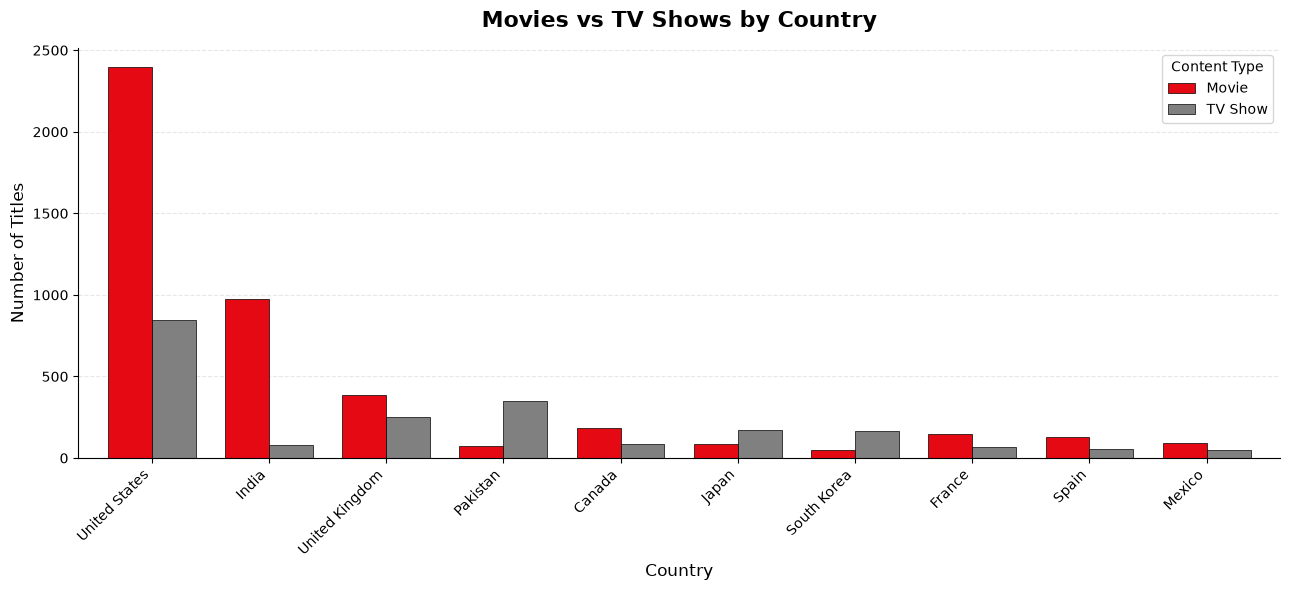

In [22]:
# Movies vs TV Shows by Country

import matplotlib.pyplot as plt
import seaborn as sns

# Prepare country-wise content data
plot_data = country_type_counts[["Movie", "TV Show"]].copy()

# Create figure
ax = plot_data.plot(
    kind="bar",
    figsize=(13, 6),
    color=["#E50914", "#808080"],
    edgecolor="black",
    linewidth=0.5,
    width=0.75
)

# Title and labels
plt.title(
    "Movies vs TV Shows by Country",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Country", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

# Legend
plt.legend(
    title="Content Type",
    labels=["Movie", "TV Show"]
)

# Styling
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()


## Key Business Insights

Based on the country-wise analysis of the Netflix dataset, the following insights were identified:

### 1. Country-wise Content Distribution
- The United States is the largest content-producing country with 3,240 titles.
- India ranks second with 1,057 titles.
- The United Kingdom ranks third with 638 titles.

### 2. Movies vs TV Shows Analysis
- The United States has the highest number of both Movies and TV Shows.
- India has significantly more Movies (976) than TV Shows (81).
- Pakistan has more TV Shows (350) than Movies (71).
- Japan and South Korea also have a higher number of TV Shows than Movies.

### 3. Global Content Contribution
- Netflix has content from multiple countries across the world.
- The United States contributes the largest share of titles.
- Asian countries such as India, Japan, South Korea and Pakistan show different content distribution patterns.

### 4. Business Observations
- Netflix has a strong content presence in the United States.
- India represents an important market for movie content.
- The higher number of TV Shows in Pakistan, Japan and South Korea indicates different content preferences across countries.
- Country-wise analysis helps understand Netflix's global content distribution.
